# Uncertainty, adjusted associations and operational recommendations

Statistical outputs describe a configured synthetic population. They do not establish causal effects or real station performance.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'tvads').exists(): ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from tvads.pipeline import current_output
OUT=current_output()
REPORTS=OUT/'reports'
summary=json.loads((REPORTS/'summary.json').read_text())
manifest=json.loads((OUT/'run_manifest.json').read_text())
fact=pd.read_parquet(OUT/'fact_commitments.parquet')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Synthetic snapshot:',summary['as_of'])


Synthetic snapshot: 2026-07-15T00:00:00Z


In [2]:
metadata=json.loads((REPORTS/'statistics_metadata.json').read_text())
metadata

{'scope': 'Synthetic due, noncancelled commitments only', 'observations': 17438, 'clusters': 120, 'bootstrap_seed': 42, 'causal_claim': False, 'bias_notes': ['The generator explicitly assigns station, daypart and duration effects.', 'Future or cancelled commitments are excluded; raw feed latency affects earlier snapshots.', 'Within-campaign resampling addresses one source of dependence, not all possible dependence.', 'Regression intervals are nominal exploratory intervals, without multiple-testing adjustment.', 'Synthetic associations do not establish real advertiser or station behavior.'], 'planned_contrast': {'comparison': 'Prime minus Overnight delivery rate', 'estimate': 0.024416765317505473, 'ci_low': 0.015246953007002063, 'ci_high': 0.03317221325839202, 'zero_excluded': True}, 'regression_status': 'CONVERGED', 'regression_outcome': 'Failure of original scheduled delivery', 'adjustment': 'Station fixed effects and 60-second duration indicator', 'standard_errors': 'Campaign-cluster

## Campaign-cluster bootstrap

Campaigns are resampled with all their commitments, preserving one source of within-campaign dependence. The interval is conditional on the simulated population and does not include uncertainty about the generator itself.

In [3]:
intervals=pd.read_csv(REPORTS/'daypart_intervals.csv')
intervals

     daypart  ...                                    method
0    Daytime  ...  400 campaign-cluster bootstrap resamples
1    Morning  ...  400 campaign-cluster bootstrap resamples
2  Overnight  ...  400 campaign-cluster bootstrap resamples
3      Prime  ...  400 campaign-cluster bootstrap resamples

[4 rows x 7 columns]

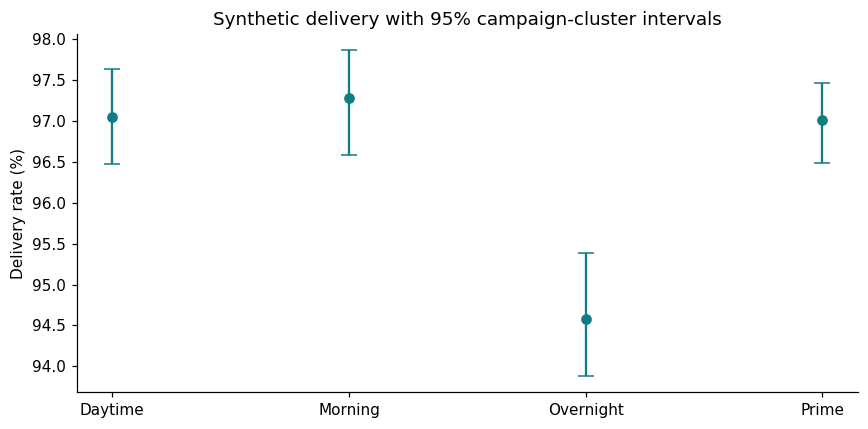

In [4]:
fig,ax=plt.subplots(figsize=(8,4))
ax.errorbar(intervals.daypart,intervals.delivery_rate*100,yerr=[(intervals.delivery_rate-intervals.ci_low)*100,(intervals.ci_high-intervals.delivery_rate)*100],fmt='o',capsize=5,color='#117C83')
ax.set_ylabel('Delivery rate (%)');ax.set_title('Synthetic delivery with 95% campaign-cluster intervals');plt.tight_layout();plt.show()

## Planned Prime-minus-Overnight contrast

The null contrast is zero. Inspect the estimate and interval rather than interpreting a small p-value as proof of a business mechanism. The generator explicitly encodes daypart risk.

In [5]:
contrast=metadata['planned_contrast']
print(f"Synthetic difference: {contrast['estimate']*100:.2f} percentage points")
print(f"95% cluster-bootstrap interval: {contrast['ci_low']*100:.2f} to {contrast['ci_high']*100:.2f} points")
contrast

Synthetic difference: 2.44 percentage points
95% cluster-bootstrap interval: 1.52 to 3.32 points


{'comparison': 'Prime minus Overnight delivery rate', 'estimate': 0.024416765317505473, 'ci_low': 0.015246953007002063, 'ci_high': 0.03317221325839202, 'zero_excluded': True}

## Adjusted original-delivery failure associations

A binomial logistic model adjusts daypart comparisons for station and 60-second duration. Standard errors cluster by campaign. Intervals are exploratory and unadjusted for multiple comparisons.

In [6]:
associations=pd.read_csv(REPORTS/'adjusted_original_failure_associations.csv')
selected=associations[associations.term.str.contains('daypart|duration_60',regex=True)].copy()
selected

                                                 term  ...       p_value
1   C(daypart, Treatment(reference='Daytime'))[T.M...  ...  5.999421e-01
2   C(daypart, Treatment(reference='Daytime'))[T.O...  ...  3.711539e-29
3   C(daypart, Treatment(reference='Daytime'))[T.P...  ...  9.202754e-01
27                                        duration_60  ...  2.968698e-09

[4 rows x 6 columns]

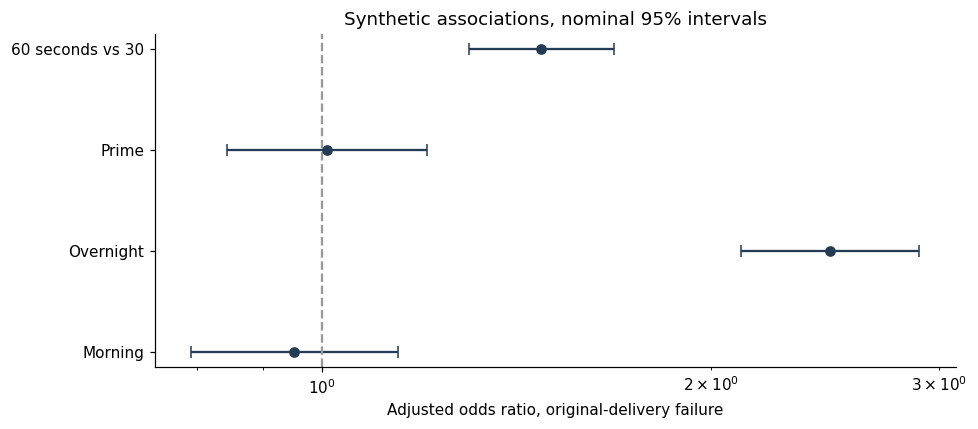

In [7]:
labels=selected.term.str.replace("C(daypart, Treatment(reference='Daytime'))[T.",'',regex=False).str.replace(']','',regex=False).replace({'duration_60':'60 seconds vs 30'})
fig,ax=plt.subplots(figsize=(9,4))
ax.errorbar(selected.odds_ratio,labels,xerr=[selected.odds_ratio-selected.ci_low,selected.ci_high-selected.odds_ratio],fmt='o',capsize=4,color='#243B55')
ax.axvline(1,color='#999999',linestyle='--');ax.set_xscale('log');ax.set_xlabel('Adjusted odds ratio, original-delivery failure');ax.set_title('Synthetic associations, nominal 95% intervals');plt.tight_layout();plt.show()

## Evidence-based action list

Delivery: review mature unconfirmed roots and approved replacement opportunities. Billing: prioritize root-level discrepancies and reconcile credits. Engineering: resolve conflicting logs and unknown keys. Product/analytics reviewers: approve cutoffs, definitions and priority rules before deployment. These are proposed roles, not a claim of completed stakeholder collaboration.

In [8]:
print((REPORTS/'recommendations.md').read_text())

# Delivery and billing review

Synthetic case study. Knowledge cutoff: 2026-07-15T00:00:00Z. Amounts below are USD.

## Findings

- 16,817 of 17,438 due, noncancelled commitments have qualifying evidence (96.44% delivery) at this cutoff.
- 737 commitments were recovered through authorized replacement airings. Each is still one contracted unit.
- Contract-defined billable value is $2,928,742.64. Matched net invoices are $3,009,170.69.
- Gross overbilling differences total $252,402.59; shortfalls total $171,974.54. These are separate directions and must not be netted away when prioritizing investigations.
- All independent count and monetary reconciliation controls match, including quarantined references.

## Recommended actions

1. Delivery reviews mature undelivered commitments, checks station evidence and agrees authorized replacements. Awaiting-log records remain provisional.
2. Billing reviews commitment-level differences and the underlying invoice lines/credits. Corrected rates ret

## Bias, limitations and next phase

Station mix, campaign composition, billing lag and observation cutoff change measured rates. Original-delivery failure differs from eventual failure after replacements. No audience ratings, conversions, paid spend, payments or randomized treatments are available. No BI dashboard is created; use the documented Tableau-ready data contract for the next phase.